# Longitudinal infant gut microbiome: alpha diversity trajectories

**Goal:** This notebook looks at changes in infant gut microbiome diversity across age and differences between infants using precalculated QIIME 2 Shannon diversity values and a Bracken taxonomic abundance table.

1. Load the Shannon diversity values, sample metadata and Bracken abundance table.

2. Alpha diversity: Shannon diversity by age group (violin plot), a mixed-effects model with infant as random effect, and individual infant trajectories.




## 0. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import biom
import qiime2 as q2
import matplotlib.pyplot as plt
import seaborn as sns
from skbio import DistanceMatrix

%matplotlib inline

# project folder
project_dir = Path("/home/jovyan/MicroOdyssey_clean")

# input metadata
metadata_dir = project_dir / "data"

# analysis outputs
taxonomy_dir = project_dir / "output" / "02_taxonomicclassification"
diversity_dir = project_dir / "output" / "04_diversityanalyses"

# figures
fig_dir = diversity_dir / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

# plot settings
sns.set_theme(style="whitegrid", context="talk")

AGES = [0, 2, 6, 12, 24]
AGE_LABELS = ["Birth", "2 months", "6 months", "12 months", "24 months"]
AGE_PALETTE = sns.color_palette("mako", len(AGES))
COMP_COLORS = {"Same infant": "#4A9D9D", "Different infants": "#53649A"}
DARK = "#17253A"

# save figures
def save_fig(name):
    plt.savefig(fig_dir / name, dpi=300, bbox_inches="tight")

## 1. Load data

In [7]:
# Alpha diversity (Shannon) per sample
shannon = q2.Artifact.load(diversity_dir /"core-metrics-results"/ "shannon_vector.qza").view(pd.Series).rename("Shannon")
# -> gives the pandas Series the label "Shannon"

# Sample metadata
meta = pd.read_csv(metadata_dir / "metadata.tsv", sep="\t", index_col=0)

# Taxonomic abundance table (Bracken): samples x taxa
biom_table = q2.Artifact.load(project_dir / "output" / "02_taxonomicclassification" / "bracken-table.qza").view(biom.Table)

abundance = biom_table.to_dataframe(dense=True).T

print("Abundance table (samples x taxa):", abundance.shape)
print("Samples with metadata:", abundance.index.isin(meta.index).sum(), "/", len(abundance))

Abundance table (samples x taxa): (234, 15034)
Samples with metadata: 234 / 234


## 2. Alpha diversity across infant development

### 2.1 Cross-sectional view: Shannon diversity by age group
The violin plot groups samples by age but does not show which samples belong to the same infant,
so it cannot say whether individual infants follow different trajectories (see 2.3).

In [8]:
# one table used for all alpha-diversity analyses: Shannon + age + infant ID

alpha = shannon.to_frame().join(meta[["age_months", "host_id"]]).dropna()
alpha["Age"] = pd.Categorical(
    alpha["age_months"].astype(int).map(dict(zip(AGES, AGE_LABELS))),
    categories=AGE_LABELS, ordered=True,
)
print(f"{len(alpha)} samples from {alpha['host_id'].nunique()} infants")
display(alpha.head())

228 samples from 55 infants


,Shannon,age_months,host_id,Age
SRR25052449,4.898495,24.0,246,24 months
SRR25052450,3.890625,12.0,246,12 months
SRR25052451,2.723996,6.0,246,6 months
SRR25052452,3.224593,2.0,246,2 months
SRR25052453,0.741673,0.0,246,Birth


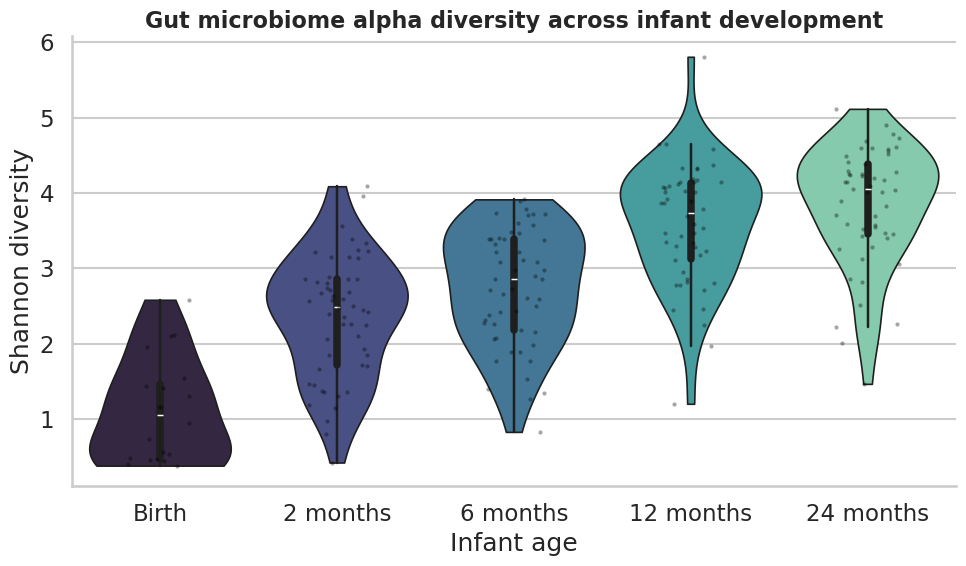

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.violinplot(
    data=alpha, x="Age", y="Shannon", order=AGE_LABELS,
    hue="Age", palette=AGE_PALETTE, legend=False,
    inner="box", cut=0, linewidth=1.2, ax=ax,
)
sns.stripplot(
    data=alpha, x="Age", y="Shannon", order=AGE_LABELS,
    color="black", size=3, alpha=0.35, jitter=0.18, ax=ax,
)

ax.set_xlabel("Infant age")
ax.set_ylabel("Shannon diversity")
ax.set_title("Gut microbiome alpha diversity across infant development", fontsize=16, weight="bold")
sns.despine()
plt.tight_layout()
save_fig("shannon_violin.png")
plt.show()

### 2.2 Mixed-effects model: Shannon ~ age, random intercept per infant

Since we have multiple samples from the same infant, we use a random intercept to account for this. The model assumes that diversity changes linearly with age, but since samples were collected at different intervals (0, 2, 6, 12 and 24 months), we should check whether this is reasonabe. (We could also try a log-transformed age or allow the effect of age to vary between infants.)

In [15]:
!qiime longitudinal linear-mixed-effects \
    --m-metadata-file $metadata_dir/metadata.tsv \
    --m-metadata-file $diversity_dir/shannon_vector.qza \
    --p-metric shannon_entropy \
    --p-state-column age_months \
    --p-individual-id-column host_id \
    --o-visualization $diversity_dir/shannon_LME.qzv

Saved Visualization to: /home/jovyan/MicroOdyssey_clean/output/03_diversityanalyses/shannon_LME.qzv


In [17]:
q2.Visualization.load(diversity_dir / "shannon_LME.qzv")

<visualization: Visualization uuid: 1e1e16ee-34c0-4293-81ba-9a4fd7fb8a20>

### 2.3 Individual infant trajectories
Thin lines connect samples from the same infant; the dark line is the mean per age.

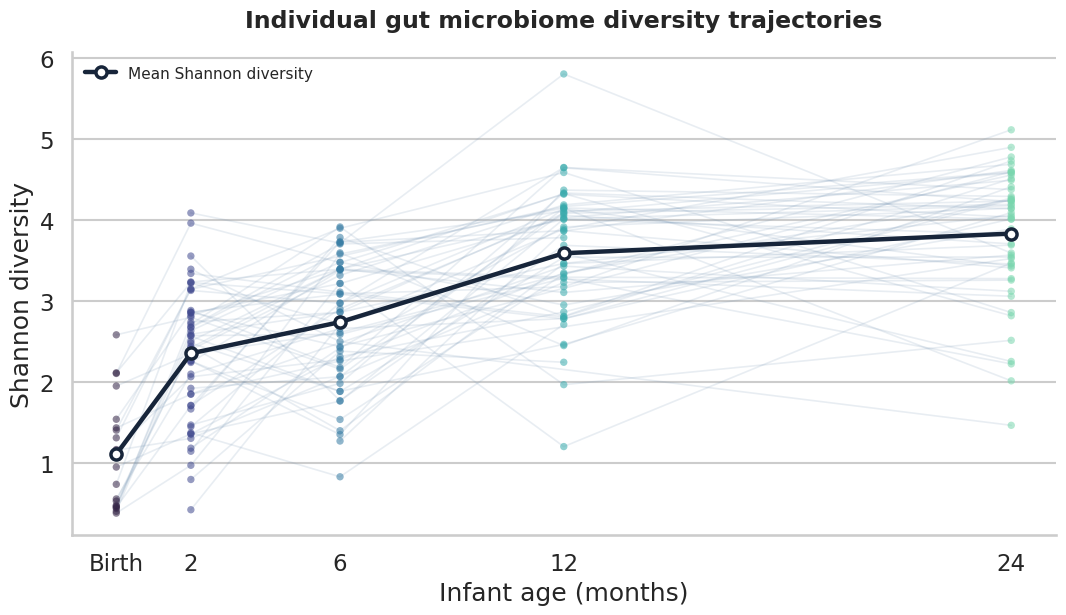

In [18]:
fig, ax = plt.subplots(figsize=(11, 6.5))

# 1. Individual infant trajectories (light)
for _, grp in alpha.groupby("host_id"):
    grp = grp.sort_values("age_months")
    ax.plot(grp["age_months"], grp["Shannon"], color="#7393B3", alpha=0.16, linewidth=1.2, zorder=1)

# 2. Individual samples, coloured by age
for age, colour in zip(AGES, AGE_PALETTE):
    sub = alpha[alpha["age_months"] == age]
    ax.scatter(sub["age_months"], sub["Shannon"], color=colour, alpha=0.55, s=28, edgecolors="none", zorder=2)

# 3. Mean per age
mean_shannon = alpha.groupby("age_months")["Shannon"].mean().reindex(AGES)
ax.plot(AGES, mean_shannon, color=DARK, linewidth=3.2, marker="o", markersize=8,
        markerfacecolor="white", markeredgewidth=2.5, label="Mean Shannon diversity", zorder=5)

ax.set_xticks(AGES)
ax.set_xticklabels(["Birth", "2", "6", "12", "24"])
ax.set_xlabel("Infant age (months)")
ax.set_ylabel("Shannon diversity")
ax.set_title("Individual gut microbiome diversity trajectories", fontsize=17, fontweight="bold", pad=18)
ax.legend(frameon=False, loc="upper left", fontsize=11)
ax.grid(axis="x", visible=False)
sns.despine()
plt.tight_layout()
save_fig("shannon_trajectories.png")
plt.show()


## 3. Effects of delivery mode and infant sex

We investigate whether delivery mode and infant sex are associated with Shannon diversity over time, using linear mixed-effects models that account for repeated measurements from the same infant.

**Model 1 — Full model**

Includes age, delivery mode, infant sex and their interactions:

`shannon_entropy ~ age_months * delivery_mode * host_sex`

**Model 2 — Simplified model**

Includes the same main effects without interactions:

`shannon_entropy ~ age_months + delivery_mode + host_sex`

Both models are compared with the age-only model from Section 2.2.


### 3.1 Model 1 – full model

In [11]:
!qiime longitudinal linear-mixed-effects \
    --m-metadata-file $metadata_dir/metadata.tsv \
    --m-metadata-file $diversity_dir/core-metrics-results/shannon_vector.qza \
    --p-metric shannon_entropy \
    --p-state-column age_months \
    --p-individual-id-column host_id \
    --p-group-columns delivery_mode,host_sex \
    --p-formula 'shannon_entropy ~ age_months * delivery_mode * host_sex' \
    --o-visualization $diversity_dir/shannon_LME_full.qzv

Saved Visualization to: /home/jovyan/MicroOdyssey_clean/output/04_diversityanalyses/shannon_LME_full.qzv


In [12]:
q2.Visualization.load(diversity_dir / "shannon_LME_full.qzv")

<visualization: Visualization uuid: c51facc1-81f4-4574-abea-8ad1ab84660a>

### 3.2 Model 2 – simple model

In [13]:
!qiime longitudinal linear-mixed-effects \
    --m-metadata-file $metadata_dir/metadata.tsv \
    --m-metadata-file $diversity_dir/core-metrics-results/shannon_vector.qza \
    --p-metric shannon_entropy \
    --p-state-column age_months \
    --p-individual-id-column host_id \
    --p-group-columns delivery_mode,host_sex \
    --p-formula 'shannon_entropy ~ age_months + delivery_mode + host_sex' \
    --o-visualization $diversity_dir/shannon_LME_simple.qzv

Saved Visualization to: /home/jovyan/MicroOdyssey_clean/output/04_diversityanalyses/shannon_LME_simple.qzv


In [14]:
q2.Visualization.load(diversity_dir / "shannon_LME_simple.qzv")

<visualization: Visualization uuid: 81e58070-69f9-4c41-9f14-6356df07b51a>

*Shannon LME (228 observations, 55 infants)*



- Both the full and simplified models converged.

- Shannon diversity increased significantly with age in both models (β = 0.092, p < 0.001 in the full model for the reference group).

- Neither model detected statistically significant delivery-mode or infant-sex coefficients.

- None of the interaction terms in the full model were statistically significant.

**Conclusion:** Shannon diversity increased significantly with infant age in both models. Neither model detected statistically significant associations with delivery mode or infant sex. No interaction terms were significant in the full model.

*Model selected for presentation: 
The full model was used to report the associations with delivery mode and infant sex, 
including their interactions with age, although none of these interactions was statistically significant.*